<a href="https://colab.research.google.com/github/dinesh6104/digital-payment-and-accounting-tools-for-small-shops-CNN-model-/blob/main/Digital_Payments_Accounting_Kirana_CNN_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Digital Payments and Accounting Tools for Kirana Stores Using CNN

## Project focus
This notebook demonstrates a CNN-based **receipt image quality checker** for a kirana-store accounting workflow. Before a shopkeeper archives a bill or receipt for bookkeeping, the model classifies the image into one of four capture-quality classes:

1. `clear` — original receipt image
2. `blurred` — synthetically blurred receipt
3. `low_contrast` — synthetically reduced-contrast receipt
4. `skewed` — synthetically rotated receipt

**Dataset:** the publicly available hand-captured restaurant receipt image dataset hosted on Zenodo (Auad et al., 2024). The notebook downloads the archive directly; no Google Drive dataset path is required.

**Important scope note:** this is a receipt-image quality screening demonstration for a digital accounting workflow. It does not identify UPI/card/cash payment modes, read transaction amounts, or verify whether a payment succeeded. The four quality labels are generated from the downloaded receipt images using controlled image transformations, not supplied as human annotations in the source dataset.

## 1. Download the public receipt dataset and prepare four image classes

In [ ]:
# Run in Google Colab or a Python environment with internet access.
import os
import io
import json
import zipfile
import random
import requests
import warnings
from pathlib import Path
from PIL import Image, ImageFilter, ImageEnhance

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED)

# Download the public Zenodo dataset through its record API.
RECORD_ID = "13688441"
api_url = f"https://zenodo.org/api/records/{RECORD_ID}"
response = requests.get(api_url, timeout=60)
response.raise_for_status()
record = response.json()

dataset_file = next(
    f for f in record["files"]
    if f["key"].lower().endswith(".zip")
)
zip_url = dataset_file["links"]["self"]
zip_path = "/content/kirana_receipts_dataset.zip"
with requests.get(zip_url, stream=True, timeout=120) as r:
    r.raise_for_status()
    with open(zip_path, "wb") as out:
        for chunk in r.iter_content(chunk_size=1024 * 1024):
            if chunk:
                out.write(chunk)

extract_dir = Path("/content/kirana_receipts_source")
extract_dir.mkdir(parents=True, exist_ok=True)
with zipfile.ZipFile(zip_path, "r") as zf:
    zf.extractall(extract_dir)

# Locate image files recursively; ignore annotation and non-image files.
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
source_images = [
    p for p in extract_dir.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
]
if not source_images:
    raise RuntimeError(
        "No image files were found in the downloaded archive. "
        "Inspect the Zenodo archive structure before continuing."
    )

print(f"Downloaded dataset: {record.get('metadata', {}).get('title', 'Zenodo receipt dataset')}")
print(f"Receipt images found: {len(source_images)}")

# Split original receipt files BEFORE making transformed copies. This prevents
# transformed versions of the same original receipt appearing in both splits.
random.shuffle(source_images)
split_index = max(1, int(0.8 * len(source_images)))
train_sources = source_images[:split_index]
test_sources = source_images[split_index:]
if not test_sources:
    raise ValueError("The dataset needs at least two source images for a train/test split.")

classes = ["clear", "blurred", "low_contrast", "skewed"]
base_dir = Path("/content/kirana_receipt_quality")
for split in ["train", "test"]:
    for class_name in classes:
        (base_dir / split / class_name).mkdir(parents=True, exist_ok=True)

def make_variants(image):
    # Standardize the source image before generating controlled capture conditions.
    image = image.convert("RGB")
    image.thumbnail((512, 512))
    canvas = Image.new("RGB", (512, 512), "white")
    x = (512 - image.width) // 2
    y = (512 - image.height) // 2
    canvas.paste(image, (x, y))

    return {
        "clear": canvas,
        "blurred": canvas.filter(ImageFilter.GaussianBlur(radius=2.0)),
        "low_contrast": ImageEnhance.Contrast(canvas).enhance(0.35),
        "skewed": canvas.rotate(8, resample=Image.Resampling.BICUBIC, expand=False, fillcolor="white")
    }

def populate_split(files, split_name):
    saved = 0
    for idx, path in enumerate(files):
        try:
            with Image.open(path) as im:
                variants = make_variants(im)
            for class_name, variant in variants.items():
                out_path = base_dir / split_name / class_name / f"receipt_{idx:04d}.jpg"
                variant.save(out_path, quality=95)
                saved += 1
        except Exception as exc:
            print(f"Skipping unreadable image {path.name}: {exc}")
    return saved

train_count = populate_split(train_sources, "train")
test_count = populate_split(test_sources, "test")
print(f"Training images created: {train_count}")
print(f"Testing images created: {test_count}")
print("Class folders:", classes)


Downloaded dataset: A labeled dataset of hand-captured images of restaurant receipts
Receipt images found: 198
Training images created: 632
Testing images created: 160
Class folders: ['clear', 'blurred', 'low_contrast', 'skewed']


## 2. Load images with data augmentation

The CNN architecture below is preserved from the supplied notebook. Images are loaded as grayscale at 128 × 128 pixels, and the data generators produce four categorical labels to match the model's existing four-unit softmax output.

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_dir = str(base_dir / "train")
test_dir = str(base_dir / "test")

train_datagen = ImageDataGenerator(
    rescale=1./255,
    shear_range=0.2,
    zoom_range=0.15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    rotation_range=10,
    horizontal_flip=False,
    fill_mode="nearest"
)
test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(128, 128),
    color_mode="grayscale",
    class_mode="categorical",
    batch_size=32,
    shuffle=True,
    seed=SEED
)
test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=(128, 128),
    color_mode="grayscale",
    class_mode="categorical",
    batch_size=32,
    shuffle=False
)

print("Class index mapping:", train_generator.class_indices)
assert train_generator.num_classes == 4, "The unchanged CNN expects exactly four classes."


Found 632 images belonging to 4 classes.
Found 160 images belonging to 4 classes.
Class index mapping: {'blurred': 0, 'clear': 1, 'low_contrast': 2, 'skewed': 3}


## 3. CNN model building — original model architecture retained

# **Model Building**

# **CNN MODEL**

In [ ]:
from keras.models import Sequential
from keras.layers import Conv2D
from keras.layers import Flatten
from keras.layers import MaxPooling2D
from keras.layers import Dense
import numpy as np

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

# Define the CNN model
CNN1 = Sequential()

# Convolutional layers
CNN1.add(Conv2D(256, (3, 3), activation='relu', input_shape=(128, 128,1
                                                            )))
CNN1.add(MaxPooling2D(pool_size=(2, 2)))

CNN1.add(Conv2D(64, (3, 3), activation='relu'))
CNN1.add(MaxPooling2D(pool_size=(2, 2)))

CNN1.add(Conv2D(256, (3, 3), activation='relu'))
CNN1.add(MaxPooling2D(pool_size=(2, 2)))

CNN1.add(Conv2D(128, (3, 3), activation='relu'))
CNN1.add(MaxPooling2D(pool_size=(2, 2)))

CNN1.add(Conv2D(256, (3, 3), activation='relu'))
CNN1.add(MaxPooling2D(pool_size=(2, 2)))

# Flattening the layers before feeding into dense layers
CNN1.add(Flatten())

# Fully connected layers
CNN1.add(Dense(128, activation='relu'))
CNN1.add(Dropout(0.2))  # Dropout to prevent overfitting
CNN1.add(Dense(64, activation='relu'))

# Output layer (adjust number of units to match the number of classes)
CNN1.add(Dense(4, activation='softmax'))  # Assuming 4 classes based on the dataset

# Compile the model
CNN1.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Model summary
CNN1.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 256)  │         2,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │       147,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 256)    │       147,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 12, 12, 128)    │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 4, 4, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 2, 2, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,027,716 (3.92 MB)

 Trainable params: 1,027,716 (3.92 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
CNN1.fit(train_generator,epochs=10)

Epoch 1/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 33s 832ms/step - accuracy: 0.2722 - loss: 1.3889
Epoch 2/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 172ms/step - accuracy: 0.3639 - loss: 1.2767
Epoch 3/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 143ms/step - accuracy: 0.4826 - loss: 1.1403
Epoch 4/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 145ms/step - accuracy: 0.5285 - loss: 1.0230
Epoch 5/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 147ms/step - accuracy: 0.5649 - loss: 0.8636
Epoch 6/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 180ms/step - accuracy: 0.5364 - loss: 0.9761
Epoch 7/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 148ms/step - accuracy: 0.5744 - loss: 0.8232
Epoch 8/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 147ms/step - accuracy: 0.6361 - loss: 0.7161
Epoch 9/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 149ms/step - accuracy: 0.6661 - loss: 0.6479
Epoch 10/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 164ms/step - accuracy: 0.6851 - loss: 0.6481


In [ ]:
# Evaluate the model on the test data
loss, accuracy1 = CNN1.evaluate(test_generator)

# Print the accuracy
print(f"Test Accuracy of CNN1: {accuracy1}")


5/5 ━━━━━━━━━━━━━━━━━━━━ 5s 77ms/step - accuracy: 0.7063 - loss: 0.5488
Test Accuracy of CNN1: 0.706250011920929


## **OPTIONAL PART BUT ADVISABLE**

#**With Batch Normalization**

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization

# Define the CNN model
CNN1 = Sequential()

# Convolutional Block 1
CNN1.add(Conv2D(256, (3, 3), activation='relu', input_shape=(128, 128, 1)))
CNN1.add(BatchNormalization())   # Added Batch Normalization
CNN1.add(MaxPooling2D(pool_size=(2, 2)))

# Convolutional Block 2
CNN1.add(Conv2D(64, (3, 3), activation='relu'))
CNN1.add(BatchNormalization())   # Added Batch Normalization
CNN1.add(MaxPooling2D(pool_size=(2, 2)))

# Convolutional Block 3
CNN1.add(Conv2D(256, (3, 3), activation='relu'))
CNN1.add(BatchNormalization())   # Added Batch Normalization
CNN1.add(MaxPooling2D(pool_size=(2, 2)))

# Convolutional Block 4
CNN1.add(Conv2D(128, (3, 3), activation='relu'))
CNN1.add(BatchNormalization())   # Added Batch Normalization
CNN1.add(MaxPooling2D(pool_size=(2, 2)))

# Convolutional Block 5
CNN1.add(Conv2D(256, (3, 3), activation='relu'))
CNN1.add(BatchNormalization())   # Added Batch Normalization
CNN1.add(MaxPooling2D(pool_size=(2, 2)))

# Flatten before Dense layers
CNN1.add(Flatten())

# Fully Connected Layers
CNN1.add(Dense(128, activation='relu'))
CNN1.add(BatchNormalization())   # Optional BN before dropout
CNN1.add(Dropout(0.2))

CNN1.add(Dense(64, activation='relu'))
CNN1.add(BatchNormalization())   # Optional BN before output layer

# Output Layer
CNN1.add(Dense(4, activation='softmax'))  # Assuming 4 classes

# Compile the model
CNN1.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Model summary
CNN1.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_5 (Conv2D)               │ (None, 126, 126, 256)  │         2,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 126, 126, 256)  │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 63, 63, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 61, 61, 64)     │       147,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 61, 61, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 28, 28, 256)    │       147,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 12, 12, 128)    │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 4, 4, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 4, 4, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 2, 2, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 1,032,324 (3.94 MB)

 Trainable params: 1,030,020 (3.93 MB)

 Non-trainable params: 2,304 (9.00 KB)

In [ ]:
CNN1.fit(train_generator,epochs=10)

Epoch 1/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 23s 584ms/step - accuracy: 0.5396 - loss: 1.1185
Epoch 2/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 148ms/step - accuracy: 0.6709 - loss: 0.7092
Epoch 3/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 143ms/step - accuracy: 0.7294 - loss: 0.5545
Epoch 4/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 137ms/step - accuracy: 0.7611 - loss: 0.5261
Epoch 5/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 187ms/step - accuracy: 0.7975 - loss: 0.4476
Epoch 6/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 148ms/step - accuracy: 0.7880 - loss: 0.4382
Epoch 7/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 149ms/step - accuracy: 0.7753 - loss: 0.4818
Epoch 8/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 149ms/step - accuracy: 0.7816 - loss: 0.4566
Epoch 9/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 190ms/step - accuracy: 0.7880 - loss: 0.4231
Epoch 10/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 147ms/step - accuracy: 0.8259 - loss: 0.3918


In [ ]:
# Evaluate the model on the test data
loss, accuracy1 = CNN1.evaluate(test_generator)

# Print the accuracy
print(f"Test Accuracy of CNN1 with batch normalization: {accuracy1}")

5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 105ms/step - accuracy: 0.2500 - loss: 5.8660
Test Accuracy of CNN1 with batch normalization: 0.25


#**With L1 regularization**

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras import regularizers

# Define the CNN model
CNN1 = Sequential()

# Convolutional layers with L1 regularization
CNN1.add(Conv2D(256, (3, 3), activation='relu', input_shape=(128, 128, 1),
                kernel_regularizer=regularizers.l1(0.001)))
CNN1.add(MaxPooling2D(pool_size=(2, 2)))

CNN1.add(Conv2D(64, (3, 3), activation='relu',
                kernel_regularizer=regularizers.l1(0.001)))
CNN1.add(MaxPooling2D(pool_size=(2, 2)))

CNN1.add(Conv2D(256, (3, 3), activation='relu',
                kernel_regularizer=regularizers.l1(0.001)))
CNN1.add(MaxPooling2D(pool_size=(2, 2)))

CNN1.add(Conv2D(128, (3, 3), activation='relu',
                kernel_regularizer=regularizers.l1(0.001)))
CNN1.add(MaxPooling2D(pool_size=(2, 2)))

CNN1.add(Conv2D(256, (3, 3), activation='relu',
                kernel_regularizer=regularizers.l1(0.001)))
CNN1.add(MaxPooling2D(pool_size=(2, 2)))

# Flatten before Dense layers
CNN1.add(Flatten())

# Fully connected layers with L1 regularization
CNN1.add(Dense(128, activation='relu',
               kernel_regularizer=regularizers.l1(0.001)))
CNN1.add(Dropout(0.2))

CNN1.add(Dense(64, activation='relu',
               kernel_regularizer=regularizers.l1(0.001)))

# Output layer (adjust number of units to match the number of classes)
CNN1.add(Dense(4, activation='softmax'))

# Compile the model
CNN1.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Model summary
CNN1.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_10 (Conv2D)              │ (None, 126, 126, 256)  │         2,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 63, 63, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 61, 61, 64)     │       147,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 28, 28, 256)    │       147,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 12, 12, 128)    │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 4, 4, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 2, 2, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,027,716 (3.92 MB)

 Trainable params: 1,027,716 (3.92 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
CNN1.fit(train_generator,epochs=10)

Epoch 1/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 14s 382ms/step - accuracy: 0.2104 - loss: 17.8192
Epoch 2/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 136ms/step - accuracy: 0.2437 - loss: 6.5808
Epoch 3/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 140ms/step - accuracy: 0.2310 - loss: 2.9697
Epoch 4/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 182ms/step - accuracy: 0.2453 - loss: 1.9812
Epoch 5/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 153ms/step - accuracy: 0.2373 - loss: 1.7328
Epoch 6/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 146ms/step - accuracy: 0.2421 - loss: 1.6287
Epoch 7/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 135ms/step - accuracy: 0.2389 - loss: 1.5698
Epoch 8/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 147ms/step - accuracy: 0.2500 - loss: 1.5329
Epoch 9/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 169ms/step - accuracy: 0.2326 - loss: 1.5178
Epoch 10/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 142ms/step - accuracy: 0.2247 - loss: 1.5140


In [ ]:
# Evaluate the model on the test data
loss, accuracy1 = CNN1.evaluate(test_generator)

# Print the accuracy
print(f"Test Accuracy of CNN1 with L1 Regularization: {accuracy1}")

5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 74ms/step - accuracy: 0.2500 - loss: 1.5129
Test Accuracy of CNN1 with L1 Regularization: 0.25


**With Batch Normalization, L2 regularization, Dropout**

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (Conv2D, MaxPooling2D, Flatten, Dense, Dropout,
                                     BatchNormalization, Activation, SpatialDropout2D)
from tensorflow.keras import regularizers
from tensorflow.keras.optimizers import Adam



CNN1 = Sequential()

# ---- Block 1 ----
CNN1.add(Conv2D(256, (3, 3), input_shape=(128, 128, 1),
                kernel_regularizer=regularizers.l2(0.001)))
CNN1.add(BatchNormalization())
CNN1.add(Activation('relu'))
CNN1.add(MaxPooling2D(pool_size=(2, 2)))
CNN1.add(SpatialDropout2D(0.15))   # small dropout after conv/pool (optional)

# ---- Block 2 ----
CNN1.add(Conv2D(64, (3, 3),
                kernel_regularizer=regularizers.l2(0.001)))
CNN1.add(BatchNormalization())
CNN1.add(Activation('relu'))
CNN1.add(MaxPooling2D(pool_size=(2, 2)))
CNN1.add(SpatialDropout2D(0.15))

# ---- Block 3 ----
CNN1.add(Conv2D(256, (3, 3),
                kernel_regularizer=regularizers.l2(0.001)))
CNN1.add(BatchNormalization())
CNN1.add(Activation('relu'))
CNN1.add(MaxPooling2D(pool_size=(2, 2)))
CNN1.add(SpatialDropout2D(0.15))

# ---- Block 4 ----
CNN1.add(Conv2D(128, (3, 3),
                kernel_regularizer=regularizers.l2(0.001)))
CNN1.add(BatchNormalization())
CNN1.add(Activation('relu'))
CNN1.add(MaxPooling2D(pool_size=(2, 2)))
CNN1.add(SpatialDropout2D(0.15))

# ---- Block 5 ----
CNN1.add(Conv2D(256, (3, 3),
                kernel_regularizer=regularizers.l2(0.001)))
CNN1.add(BatchNormalization())
CNN1.add(Activation('relu'))
CNN1.add(MaxPooling2D(pool_size=(2, 2)))
CNN1.add(SpatialDropout2D(0.15))

# ---- Classifier ----
CNN1.add(Flatten())

CNN1.add(Dense(128, kernel_regularizer=regularizers.l2(0.001)))
CNN1.add(BatchNormalization())
CNN1.add(Activation('relu'))
CNN1.add(Dropout(0.5))             # higher dropout on dense layers

CNN1.add(Dense(64, kernel_regularizer=regularizers.l2(0.001)))
CNN1.add(BatchNormalization())
CNN1.add(Activation('relu'))
CNN1.add(Dropout(0.5))

CNN1.add(Dense(4, activation='softmax'))

# Compile with slightly lower LR (pairs well with dropout/BN)
CNN1.compile(optimizer=Adam(learning_rate=0.0004),
             loss='categorical_crossentropy',
             metrics=['accuracy'])

CNN1.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_15 (Conv2D)              │ (None, 126, 126, 256)  │         2,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 126, 126, 256)  │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 126, 126, 256)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 63, 63, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout2d               │ (None, 63, 63, 256)    │             0 │
│ (SpatialDropout2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 61, 61, 64)     │       147,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 61, 61, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 61, 61, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout2d_1             │ (None, 30, 30, 64)     │             0 │
│ (SpatialDropout2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 28, 28, 256)    │       147,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout2d_2             │ (None, 14, 14, 256)    │             0 │
│ (SpatialDropout2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 12, 12, 128)    │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_18 (MaxPooling2D) │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout2d_3             │ (None, 6, 6, 128)      │             0 │
│ (SpatialDropout2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 4, 4, 256)      │       295,16

 Total params: 1,032,324 (3.94 MB)

 Trainable params: 1,030,020 (3.93 MB)

 Non-trainable params: 2,304 (9.00 KB)

In [ ]:
CNN1.fit(train_generator,epochs=50)

Epoch 1/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 31s 761ms/step - accuracy: 0.3782 - loss: 2.4713
Epoch 2/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 159ms/step - accuracy: 0.4525 - loss: 2.2323
Epoch 3/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 188ms/step - accuracy: 0.4937 - loss: 2.0984
Epoch 4/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 139ms/step - accuracy: 0.5253 - loss: 2.0030
Epoch 5/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 151ms/step - accuracy: 0.5744 - loss: 1.8612
Epoch 6/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 140ms/step - accuracy: 0.6377 - loss: 1.7609
Epoch 7/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 192ms/step - accuracy: 0.6123 - loss: 1.7293
Epoch 8/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 152ms/step - accuracy: 0.6440 - loss: 1.6581
Epoch 9/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 143ms/step - accuracy: 0.6503 - loss: 1.6778
Epoch 10/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 147ms/step - accuracy: 0.6519 - loss: 1.6535
Epoch 11/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 187ms/step - accuracy: 0.6772 - loss: 1.6134
Epoch 12/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 138ms/ste

In [ ]:
# Evaluate the model on the test data
loss, accuracy1 = CNN1.evaluate(test_generator)

# Print the accuracy
print(f"Test Accuracy of CNN1 with L2 Regularization: {accuracy1}")

5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 63ms/step - accuracy: 0.9563 - loss: 0.8308
Test Accuracy of CNN1 with L2 Regularization: 0.956250011920929


### 4. Demo: Upload a Receipt Image and Test the CNN Model

Saving WhatsApp Image 2026-11-11 at 11.19.05 AM.jpeg to WhatsApp Image 2026-11-11 at 11.19.05 AM (1).jpeg
User uploaded file "WhatsApp Image 2026-11-11 at 11.19.05 AM (1).jpeg" with length 327101 bytes
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step


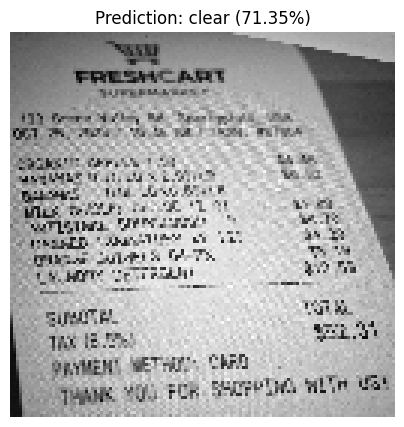

Class Probabilities:
 - blurred: 1.10%
 - clear: 71.35%
 - low_contrast: 1.07%
 - skewed: 26.48%


In [ ]:
from google.colab import files
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image

# 1. Upload your image file
uploaded = files.upload()

for fn in uploaded.keys():
    print(f'User uploaded file "{fn}" with length {len(uploaded[fn])} bytes')

    # 2. Load and preprocess the image to match model requirements (128x128, grayscale)
    img_path = fn
    img = image.load_img(img_path, target_size=(128, 128), color_mode="grayscale")

    # Convert image to array and rescale pixel values
    img_array = image.img_to_array(img) / 255.0
    img_array = np.expand_dims(img_array, axis=0) # Add batch dimension

    # 3. Predict class probabilities
    predictions = CNN1.predict(img_array)
    score = predictions[0]

    # Define the classes matching your dataset labels
    class_labels = ['blurred', 'clear', 'low_contrast', 'skewed']
    predicted_class = class_labels[np.argmax(score)]
    confidence = 100 * np.max(score)

    # 4. Display results
    plt.figure(figsize=(5, 5))
    plt.imshow(img, cmap='gray')
    plt.title(f"Prediction: {predicted_class} ({confidence:.2f}%)")
    plt.axis('off')
    plt.show()

    print("Class Probabilities:")
    for label, prob in zip(class_labels, score):
        print(f" - {label}: {prob*100:.2f}%")